# Milestone 1: create a simulated customer experiment

**After the World Cup brings in free-trial customers, which action improves paid retention enough to be worth its cost?**

We invent a streaming service and its customers so we can practice running an experiment. This notebook creates the data. Notebook 2 reads that saved data and analyzes it. Nothing here is evidence about real customers. No ML or dbt is added.


## 1. How do I run this notebook?


Run Notebook 1 to create the data, then Notebook 2 to analyze it. Run each notebook from top to bottom.

Locally, install `requirements.txt` from the repository root and start Jupyter Lab (see the README). In Colab, clone this branch once, change to the repository folder, and install the requirements. Use the **same checkout and data folder** for both notebooks. If you use separate Colab runtimes, copy the generated `data/` files into the second checkout, or rerun Notebook 1 there before Notebook 2. Uploading a notebook alone does not include the Python helpers.

The next cell imports the libraries used below. Imports make their functions available; they do not generate or analyze data yet.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


The next cell finds the project folder and imports our data generator and checks. The generator lives in a Python file so we can reuse it without copying its code.


In [2]:
ROOT = Path.cwd()
if not (ROOT / 'retention').is_dir():
    ROOT = ROOT.parent  # Jupyter may start inside notebooks/.
if not (ROOT / 'retention').is_dir():
    raise FileNotFoundError('Open Jupyter from the repository root or notebooks/ folder.')
sys.path.insert(0, str(ROOT))

from retention.simulation import ARMS, PRE_OFFER_FEATURES
from retention.simulation import simulate_experiment, validate_experiment
from retention.reporting import OFFER_NAMES


## 2. Who receives an offer, and which offers can they receive?

We create 12,000 fictional trial customers who are **still active and have not canceled** on trial day 13, one day before their 14-day trial ends. Here, active means they viewed content on at least one of the previous three days. We create eligible users directly; we do not simulate every signup or estimate how many users qualify.

Signups fall May 28–July 5, 2026; trial ends fall June 11–July 19, around the World Cup. World Cup viewing includes previews and coverage as well as matches.

Each eligible customer has an equal, independent one-in-three chance of:

| Group | What happens |
|---|---|
| No special offer | Normal $15 monthly price |
| Content recommendation | Suggest relevant non-World-Cup movies, series, and other continuing content; same price |
| 20% discount | Reduce the first paid month by 20%; normal price after that |

We care most about **still paying 90 days after the scheduled trial end**. Whether the customer starts paying by trial end is a second outcome. The same clock applies to every group. We keep all assigned customers in later comparisons, even if they never pay.

The next cell creates the customers and a separate answer key. The seed makes this simulated run repeatable; changing it creates a different random run.


In [3]:
N_CUSTOMERS = 12_000
SEED = 2026
customers, oracle_answer_key = simulate_experiment(N_CUSTOMERS, SEED)
print(f'Created {len(customers):,} fictional customers.')


Created 12,000 fictional customers.


## 3. What does one customer row mean?

One row describes one customer: behavior before the offer, their assigned offer, and what happened afterward. The next cell shows a few useful columns for the first customer.


In [4]:
example_columns = [
    'customer_id', 'active_days_pre', 'non_world_cup_hours_pre',
    'assigned_offer', 'converted', 'retained_day90', 'subscription_revenue_90',
]
display(customers[example_columns].head(1))


,customer_id,active_days_pre,non_world_cup_hours_pre,assigned_offer,converted,retained_day90,subscription_revenue_90
0,customer_0000001,9,2.49,discount_20pct,False,False,0.0


The next cell translates that row into a short story. `True` means yes and `False` means no. A customer who never converts can still appear in the data and in all group averages.


In [5]:
person = customers.iloc[0]
print(f"{person.customer_id} watched on {person.active_days_pre} of the 13 pre-offer days.")
print(f"They watched {person.non_world_cup_hours_pre:.2f} hours outside World Cup content.")
print(f"Assigned action: {OFFER_NAMES[person.assigned_offer]}.")
print(f"Started paying by trial end: {person.converted}.")
print(f"Still paying 90 days after trial end: {person.retained_day90}.")
print(f"Subscription revenue after discounts: ${person.subscription_revenue_90:.2f}.")


customer_0000001 watched on 9 of the 13 pre-offer days.
They watched 2.49 hours outside World Cup content.
Assigned action: 20% discount.
Started paying by trial end: False.
Still paying 90 days after trial end: False.
Subscription revenue after discounts: $0.00.


## 4. What did we know before sending the offer?

We record the **13 completed days before the offer**, never behavior caused by the offer. `_pre` means “before the offer.” These columns include viewing activity, World Cup share, non-World-Cup hours, the number of other content categories watched (content breadth), pricing-page visits, and discovery sessions.

The simulator also invents hidden engagement, World Cup interest, and price sensitivity. It does not export them as customer features. Both recommendations and discounts can help some customers and harm others. We planted those effects; they are not discoveries. Exact assumptions are documented in `docs/assumptions.md`.

The next cell selects only the allowed pre-offer columns and previews three rows. IDs, offer assignment, dates, outcomes, and answer-key probabilities are not future model features. We are not building a model here.


In [6]:
pre_offer_features = customers[list(PRE_OFFER_FEATURES)].copy()
display(pre_offer_features.head(3))
assert not any(column.startswith('p_') for column in pre_offer_features)


,active_days_pre,active_days_last3_pre,watch_hours_pre,world_cup_share_pre,non_world_cup_hours_pre,content_breadth_pre,pricing_page_visits_pre,discovery_sessions_pre
0,9,2,21.88,0.886,2.49,2,2,1
1,5,3,11.01,0.577,4.66,5,2,2
2,7,3,8.07,0.242,6.12,4,4,6


## 5. What do the money columns include?

A fictional month has 30 days: $15/month means $0.50 per paid day. We count paid days in the 90 days after trial end. Successful customers start paying at trial end; nonconverters never pay later in this simple simulation.

| Column | Meaning |
|---|---|
| `reference_revenue_90` | Paid days × $0.50, before any discount |
| `discount_cost_90` | Revenue given up by discounting the first 30 paid days; at most $3 per converter |
| `subscription_revenue_90` | Reference revenue minus the discount |
| `delivery_cost_90` | $0.10 for every content recommendation assignment, including nonconverters |
| `offer_cost_90` | Discount cost plus delivery cost |
| `revenue_less_delivery_cost_90` | Subscription revenue minus delivery cost |

Do not subtract the discount twice. These amounts are **revenue, not profit**: licensing, acquisition, baseline hosting, taxes, and other operating costs are missing. A recommendation nonconverter has $0 subscription revenue but still costs $0.10 to contact.

The next cell shows one converter and one nonconverter per group, where available. This small preview is only an example; later averages include everyone.


In [7]:
money_columns = [
    'assigned_offer', 'converted', 'paid_days_90', 'discount_cost_90',
    'subscription_revenue_90', 'delivery_cost_90', 'revenue_less_delivery_cost_90',
]
examples = customers.groupby(['assigned_offer', 'converted']).head(1)
display(examples[money_columns].round(2))


,assigned_offer,converted,paid_days_90,discount_cost_90,subscription_revenue_90,delivery_cost_90,revenue_less_delivery_cost_90
0,discount_20pct,False,0,0.0,0.0,0.0,0.0
1,discount_20pct,True,63,3.0,28.5,0.0,28.5
2,content_recommendation,False,0,0.0,0.0,0.1,-0.1
3,control,False,0,0.0,0.0,0.0,0.0
11,content_recommendation,True,90,0.0,45.0,0.1,44.9
14,control,True,36,0.0,18.0,0.0,18.0


## 6. Does the generated data follow our rules?

The next cell checks one row per customer, eligibility, dates, valid probabilities, retention only after conversion, and money calculations. A failed check means we should fix the data before analyzing it. Passing checks does not make the invented assumptions true in real life.


In [8]:
validate_experiment(customers, oracle_answer_key)
print('Customer, timeline, outcome, answer-key, and money checks passed.')


Customer, timeline, outcome, answer-key, and money checks passed.


## 7. Did random assignment create roughly similar groups?

The next cell counts customers in each group and compares average pre-offer behavior. `mean()` means average; `groupby()` calculates it separately for each group.


In [9]:
counts = customers.assigned_offer.value_counts().reindex(ARMS)
display(counts.rename(index=OFFER_NAMES).to_frame('Assigned customers'))
feature_means = customers.groupby('assigned_offer')[list(PRE_OFFER_FEATURES)].mean()
display(feature_means.reindex(ARMS).rename(index=OFFER_NAMES).round(2))


,Assigned customers
assigned_offer,
No special offer,3999
Content recommendation,3970
20% discount,4031


,active_days_pre,active_days_last3_pre,watch_hours_pre,world_cup_share_pre,non_world_cup_hours_pre,content_breadth_pre,pricing_page_visits_pre,discovery_sessions_pre
assigned_offer,,,,,,,,
No special offer,7.06,2.01,9.26,0.59,3.77,2.62,1.54,2.88
Content recommendation,7.00,2.01,8.96,0.60,3.59,2.62,1.57,2.82
20% discount,6.99,2.02,9.08,0.60,3.66,2.63,1.56,2.83


Small count and behavior differences are normal because assignment is random. We do not redraw assignments to make them look equal. The next cell draws the counts; the dashed line is the expected one-third share.


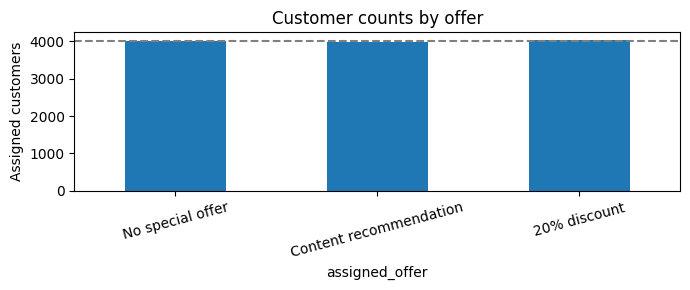

In [10]:
counts.rename(index=OFFER_NAMES).plot.bar(figsize=(7, 3), rot=15)
plt.axhline(len(customers) / 3, color='gray', linestyle='--')
plt.ylabel('Assigned customers')
plt.title('Customer counts by offer')
plt.tight_layout()
plt.show()


## 8. What happened in each group?

The next cell shows average outcomes for **all assigned customers**, including those who never paid. Rates are shown as percentages; money is shown as average dollars per assigned customer. This table describes one simulated run, without testing whether the differences are convincing.


In [11]:
summary = customers.groupby('assigned_offer').agg(
    customers=('customer_id', 'size'),
    retention_percent=('retained_day90', 'mean'),
    conversion_percent=('converted', 'mean'),
    subscription_revenue=('subscription_revenue_90', 'mean'),
    offer_cost=('offer_cost_90', 'mean'),
    revenue_less_delivery=('revenue_less_delivery_cost_90', 'mean'),
).reindex(ARMS)
summary[['retention_percent', 'conversion_percent']] *= 100
display(summary.rename(index=OFFER_NAMES).round(2))


,customers,retention_percent,conversion_percent,subscription_revenue,offer_cost,revenue_less_delivery
assigned_offer,,,,,,
No special offer,3999,17.65,35.88,11.58,0.00,11.58
Content recommendation,3970,17.98,35.72,11.79,0.10,11.69
20% discount,4031,15.36,31.08,9.23,0.84,9.23


The retention percentage cannot exceed conversion: someone must start paying before they can still be paying later. Higher conversion alone does not answer whether an offer is worth its cost. Notebook 2 will examine uncertainty, rather than choosing the highest sample average.


## 9. Where do we save the data for Notebook 2?

The next cell writes the customer table to `data/generated/customers.csv` and the answer key to **a different folder**, `data/evaluation_only/oracle_probabilities.csv`. Rerunning this notebook replaces those local files; then rerun Notebook 2 so its results match the new data. Both folders are ignored by Git.


In [12]:
customer_dir = ROOT / 'data' / 'generated'
oracle_dir = ROOT / 'data' / 'evaluation_only'
customer_dir.mkdir(parents=True, exist_ok=True)
oracle_dir.mkdir(parents=True, exist_ok=True)
customers.to_csv(customer_dir / 'customers.csv', index=False)
oracle_answer_key.to_csv(oracle_dir / 'oracle_probabilities.csv', index=False)
print('Saved customers.csv and the separate oracle_probabilities.csv.')


Saved customers.csv and the separate oracle_probabilities.csv.


The next cell saves the seed and settings beside the customer file. This small record helps us remember which simulated run created the data.


In [13]:
metadata = {
    'n_customers': N_CUSTOMERS, 'seed': SEED,
    'numpy': np.__version__, 'pandas': pd.__version__,
    'followup_days': 90, 'followup_anchor': 'scheduled_trial_end_date',
    'offer_day': 13, 'trial_days': 14, 'arms': list(ARMS),
    'assignment_probability': 1 / 3, 'pre_offer_features': list(PRE_OFFER_FEATURES),
    'scenario': 'eligible_day13_three_actions_trial_end_followup',
}
(customer_dir / 'run_metadata.json').write_text(json.dumps(metadata, indent=2) + '\n')


642

## 10. Does the simulator roughly match its own answer key?

This is a **simulation check only**. The answer key stores each customer's invented probabilities under all three offers. It is not information a real prediction model could know, and it never becomes a customer feature.

The next cell compares observed rates with average probabilities for the action each customer actually received. Random outcomes should be reasonably close, not identical. This does not test whether one offer beats another.


In [14]:
evaluation_only = customers[['customer_id', 'assigned_offer', 'converted', 'retained_day90']].merge(
    oracle_answer_key, left_on=['customer_id', 'assigned_offer'],
    right_on=['customer_id', 'offer'], validate='one_to_one',
)
calibration = evaluation_only.groupby('assigned_offer').agg(
    expected_conversion=('p_conversion', 'mean'),
    observed_conversion=('converted', 'mean'),
    expected_retention=('p_retained_day90', 'mean'),
    observed_retention=('retained_day90', 'mean'),
)
display(calibration.reindex(ARMS).rename(index=OFFER_NAMES).round(3))
del evaluation_only


,expected_conversion,observed_conversion,expected_retention,observed_retention
assigned_offer,,,,
No special offer,0.348,0.359,0.170,0.177
Content recommendation,0.359,0.357,0.186,0.180
20% discount,0.314,0.311,0.149,0.154


## Optional appendix: how are the fake outcomes calculated?

Hidden preferences and pre-offer viewing create probability scores; a smooth formula turns each score into a probability. A random yes/no draw determines conversion. A random cancellation time determines paid days and day-90 retention.

Recommendations help users with hidden World Cup interest above 0.55 and can harm others. Discounts help users with hidden price sensitivity above 0.60 and can harm others. At the thresholds the planted effect is zero. Daily cancellation risk is constant, not a real tournament-end spike. Cancellation exactly at the day-90 boundary is not counted as retained, even if 90 paid days have accrued.

The exact distributions and formulas remain in [`docs/assumptions.md`](../docs/assumptions.md). They specify the invented world rather than lessons learned from real customers.

**Next:** Run Notebook 2 to analyze the CSV we just saved. No ML or dbt is implemented.
